# Hypothesis Testing

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Exploratory Data Analysis provides visual insights into the dataset, but statistical hypothesis testing is required to determine whether the observed relationships are statistically significant.

This notebook applies classical statistical tests to investigate relationships between applicant characteristics and credit default.

The objectives are to:

- Test whether financial characteristics differ between default and non-default applicants.
- Examine associations between categorical variables and loan default.
- Compare income across different education groups.
- Evaluate correlation significance among selected numerical variables.
- Interpret findings using statistical evidence.

The results of these analyses provide a statistical foundation for feature engineering and predictive modeling.

# Import Required Libraries

The following libraries are used for statistical hypothesis testing and data visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

ALPHA = 0.05

# Load Processed Dataset

The cleaned and merged applicant-level dataset generated during preprocessing is loaded for statistical analysis.

In [3]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

merged_df = pd.read_csv(DATA_DIR / "credit_risk_processed.csv")

print("Dataset Shape:", merged_df.shape)

Dataset Shape: (307511, 362)


# Statistical Significance Level

All hypothesis tests are conducted using a significance level of **α = 0.05**.

Decision rule:

- If p-value < 0.05 → Reject the null hypothesis.
- If p-value ≥ 0.05 → Fail to reject the null hypothesis.

In [2]:
# ============================================================
# Significance Level
# ============================================================

ALPHA = 0.05

print(f"Significance Level (α): {ALPHA}")

Significance Level (α): 0.05


# Hypothesis 1

## Does Annual Income Differ Between Default and Non-Default Applicants?

### Null Hypothesis (H₀)

The mean annual income is the same for default and non-default applicants.

### Alternative Hypothesis (H₁)

The mean annual income differs significantly between default and non-default applicants.

An independent two-sample t-test is used to compare the average annual income of the two groups.

In [4]:
# ============================================================
# Independent t-test
# ============================================================

default = merged_df.loc[
    merged_df["TARGET"] == 1,
    "AMT_INCOME_TOTAL"
]

non_default = merged_df.loc[
    merged_df["TARGET"] == 0,
    "AMT_INCOME_TOTAL"
]

t_stat, p_value = stats.ttest_ind(
    default,
    non_default,
    equal_var=False,
    nan_policy="omit"
)

print(f"T-statistic : {t_stat:.4f}")
print(f"P-value     : {p_value:.6f}")

if p_value < ALPHA:
    print("\nReject H₀")
else:
    print("\nFail to Reject H₀")

T-statistic : -0.7307
P-value     : 0.464990

Fail to Reject H₀


# Visualization of Annual Income by Default Status

A boxplot is used to compare the distribution of annual income between applicants who defaulted and those who did not.

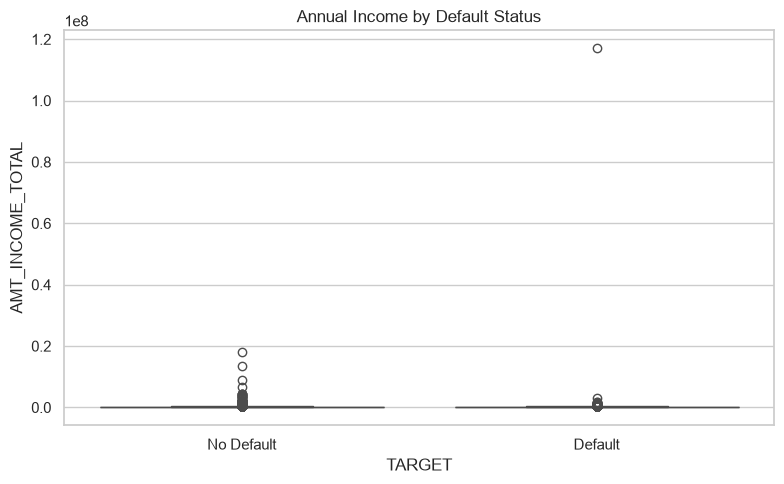

In [5]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=merged_df,
    x="TARGET",
    y="AMT_INCOME_TOTAL"
)

plt.xticks(
    [0,1],
    ["No Default","Default"]
)

plt.title("Annual Income by Default Status")

plt.tight_layout()

plt.show()

# Hypothesis 2

## Does the Loan Amount Differ Between Default and Non-Default Applicants?

### Null Hypothesis (H₀)

The mean loan amount (`AMT_CREDIT`) is the same for default and non-default applicants.

### Alternative Hypothesis (H₁)

The mean loan amount differs significantly between default and non-default applicants.

An independent two-sample t-test is used to compare the average loan amount of the two groups.

In [6]:
# ============================================================
# Independent t-test: Loan Amount
# ============================================================

default_credit = merged_df.loc[
    merged_df["TARGET"] == 1,
    "AMT_CREDIT"
]

non_default_credit = merged_df.loc[
    merged_df["TARGET"] == 0,
    "AMT_CREDIT"
]

t_stat_credit, p_value_credit = stats.ttest_ind(
    default_credit,
    non_default_credit,
    equal_var=False,
    nan_policy="omit"
)

print(f"T-statistic : {t_stat_credit:.4f}")
print(f"P-value     : {p_value_credit:.6f}")

if p_value_credit < ALPHA:
    print("\nReject H₀")
else:
    print("\nFail to Reject H₀")

T-statistic : -19.2732
P-value     : 0.000000

Reject H₀


# Visualization of Loan Amount by Default Status

The distribution of loan amounts is compared between default and non-default applicants using a boxplot.

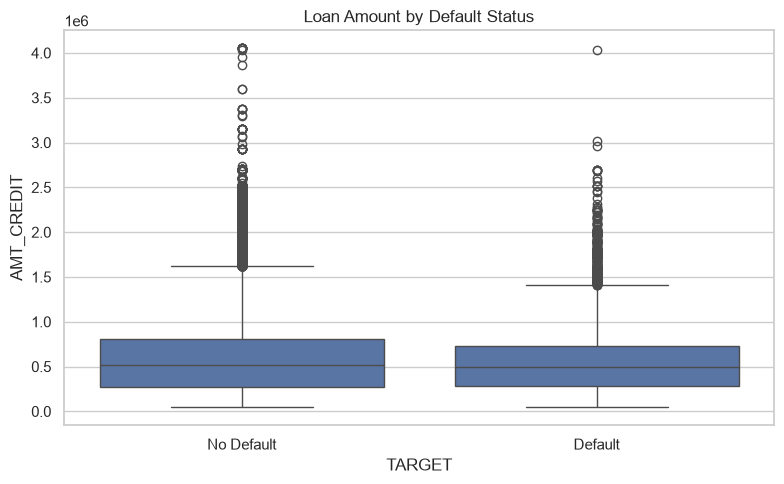

In [7]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=merged_df,
    x="TARGET",
    y="AMT_CREDIT"
)

plt.xticks([0,1],["No Default","Default"])

plt.title("Loan Amount by Default Status")

plt.tight_layout()

plt.show()

# Hypothesis 3

## Is Gender Associated with Credit Default?

### Null Hypothesis (H₀)

Applicant gender and loan default are independent.

### Alternative Hypothesis (H₁)

Applicant gender and loan default are significantly associated.

A Chi-Square Test of Independence is used to evaluate this relationship.

In [8]:
# ============================================================
# Chi-Square Test: Gender vs Default
# ============================================================

gender_table = pd.crosstab(
    merged_df["CODE_GENDER"],
    merged_df["TARGET"]
)

chi2_gender, p_gender, dof_gender, expected_gender = stats.chi2_contingency(
    gender_table
)

print(f"Chi-square Statistic : {chi2_gender:.4f}")
print(f"Degrees of Freedom   : {dof_gender}")
print(f"P-value              : {p_gender:.6f}")

if p_gender < ALPHA:
    print("\nReject H₀")
else:
    print("\nFail to Reject H₀")

Chi-square Statistic : 920.7913
Degrees of Freedom   : 2
P-value              : 0.000000

Reject H₀


# Hypothesis 4

## Is Applicant Income Type Associated with Credit Default?

### Null Hypothesis (H₀)

Income type and loan default are independent.

### Alternative Hypothesis (H₁)

Income type and loan default are significantly associated.

The Chi-Square Test of Independence is applied.

In [9]:
# ============================================================
# Chi-Square Test: Income Type vs Default
# ============================================================

income_table = pd.crosstab(
    merged_df["NAME_INCOME_TYPE"],
    merged_df["TARGET"]
)

chi2_income, p_income, dof_income, expected_income = stats.chi2_contingency(
    income_table
)

print(f"Chi-square Statistic : {chi2_income:.4f}")
print(f"Degrees of Freedom   : {dof_income}")
print(f"P-value              : {p_income:.6f}")

if p_income < ALPHA:
    print("\nReject H₀")
else:
    print("\nFail to Reject H₀")

Chi-square Statistic : 1253.4708
Degrees of Freedom   : 7
P-value              : 0.000000

Reject H₀


# Hypothesis 5

## Does Annual Income Differ Across Education Levels?

### Null Hypothesis (H₀)

The mean annual income is equal across all education groups.

### Alternative Hypothesis (H₁)

At least one education group has a significantly different mean annual income.

A One-Way ANOVA is used to compare the average annual income across education levels.

In [10]:
# ============================================================
# One-Way ANOVA
# ============================================================

education_groups = [
    group["AMT_INCOME_TOTAL"].values
    for _, group in merged_df.groupby("NAME_EDUCATION_TYPE")
]

f_stat, p_anova = stats.f_oneway(*education_groups)

print(f"F-statistic : {f_stat:.4f}")
print(f"P-value     : {p_anova:.6f}")

if p_anova < ALPHA:
    print("\nReject H₀")
else:
    print("\nFail to Reject H₀")

F-statistic : 753.2160
P-value     : 0.000000

Reject H₀


# Visualization of Income Across Education Levels

A boxplot illustrates how applicant income varies across education categories.

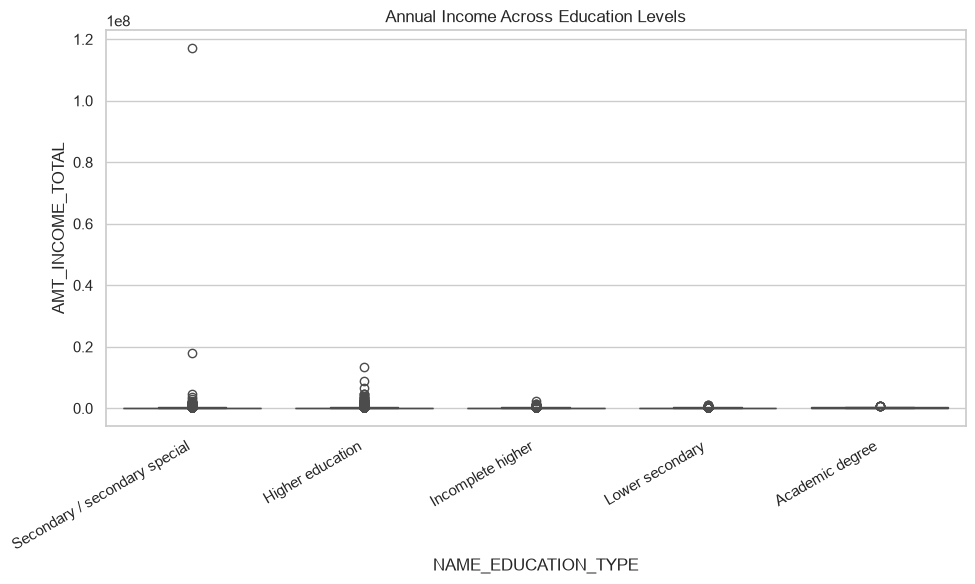

In [11]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=merged_df,
    x="NAME_EDUCATION_TYPE",
    y="AMT_INCOME_TOTAL"
)

plt.xticks(rotation=30, ha="right")

plt.title("Annual Income Across Education Levels")

plt.tight_layout()

plt.show()

# Hypothesis 6

## Is Applicant Age Significantly Correlated with Loan Amount?

### Null Hypothesis (H₀)

There is no linear correlation between applicant age and loan amount.

### Alternative Hypothesis (H₁)

There is a statistically significant linear correlation between applicant age and loan amount.

Pearson's correlation test is used to evaluate the relationship.

In [12]:
# ============================================================
# Pearson Correlation Test
# ============================================================

age_years = np.abs(merged_df["DAYS_BIRTH"]) / 365

corr_coef, p_corr = stats.pearsonr(
    age_years,
    merged_df["AMT_CREDIT"]
)

print(f"Correlation Coefficient : {corr_coef:.4f}")
print(f"P-value                 : {p_corr:.6f}")

if p_corr < ALPHA:
    print("\nReject H₀")
else:
    print("\nFail to Reject H₀")

Correlation Coefficient : 0.0554
P-value                 : 0.000000

Reject H₀


# Summary of Hypothesis Tests

The following table summarizes the statistical tests performed in this notebook, along with the corresponding p-values and decisions.

In [13]:
# ============================================================
# Summary Table
# ============================================================

summary = pd.DataFrame({
    "Hypothesis": [
        "Income vs Default",
        "Loan Amount vs Default",
        "Gender vs Default",
        "Income Type vs Default",
        "Education vs Income",
        "Age vs Loan Amount"
    ],
    "Statistical Test": [
        "Independent t-test",
        "Independent t-test",
        "Chi-Square Test",
        "Chi-Square Test",
        "One-Way ANOVA",
        "Pearson Correlation"
    ],
    "P-value": [
        p_value,
        p_value_credit,
        p_gender,
        p_income,
        p_anova,
        p_corr
    ]
})

summary["Decision"] = np.where(
    summary["P-value"] < ALPHA,
    "Reject H₀",
    "Fail to Reject H₀"
)

summary

,Hypothesis,Statistical Test,P-value,Decision
0,Income vs Default,Independent t-test,4.649904e-01,Fail to Reject H₀
1,Loan Amount vs Default,Independent t-test,2.721911e-82,Reject H₀
2,Gender vs Default,Chi-Square Test,1.129022e-200,Reject H₀
3,Income Type vs Default,Chi-Square Test,1.928146e-266,Reject H₀
4,Education vs Income,One-Way ANOVA,0.000000e+00,Reject H₀
5,Age vs Loan Amount,Pearson Correlation,7.752093e-208,Reject H₀


# Effect Size Analysis

Statistical significance alone does not indicate the practical importance of a result.

To complement the hypothesis tests, effect size measures are calculated:

- **Cohen's d** for Independent t-tests
- **Cramér's V** for Chi-Square Tests
- **Eta-squared (η²)** for One-Way ANOVA

These measures quantify the magnitude of observed differences or associations and provide a more comprehensive interpretation of the statistical results.

In [14]:
# ============================================================
# Effect Size Functions
# ============================================================

import numpy as np

def cohens_d(group1, group2):
    """
    Compute Cohen's d for two independent samples.
    """

    group1 = np.asarray(group1)
    group2 = np.asarray(group2)

    n1 = len(group1)
    n2 = len(group2)

    var1 = np.var(group1, ddof=1)
    var2 = np.var(group2, ddof=1)

    pooled_sd = np.sqrt(
        ((n1 - 1) * var1 + (n2 - 1) * var2) /
        (n1 + n2 - 2)
    )

    return (group1.mean() - group2.mean()) / pooled_sd


def cramers_v(confusion_matrix):

    chi2 = stats.chi2_contingency(confusion_matrix)[0]

    n = confusion_matrix.sum().sum()

    r, k = confusion_matrix.shape

    return np.sqrt(
        chi2 /
        (n * (min(r, k) - 1))
    )


def eta_squared(groups):

    all_values = np.concatenate(groups)

    grand_mean = np.mean(all_values)

    ss_between = sum(
        len(g) * (np.mean(g) - grand_mean) ** 2
        for g in groups
    )

    ss_total = np.sum(
        (all_values - grand_mean) ** 2
    )

    return ss_between / ss_total

# Effect Size for Income vs Default

Cohen's d measures the standardized difference in mean annual income between default and non-default applicants.

Interpretation:

- 0.20 → Small
- 0.50 → Medium
- 0.80 → Large

In [15]:
income_d = cohens_d(default, non_default)

print(f"Cohen's d = {income_d:.3f}")

Cohen's d = -0.015


# Effect Size for Loan Amount vs Default

Cohen's d is also calculated for the loan amount comparison.

In [16]:
credit_d = cohens_d(
    default_credit,
    non_default_credit
)

print(f"Cohen's d = {credit_d:.3f}")

Cohen's d = -0.112


# Effect Size for Gender vs Default

Cramér's V measures the strength of association between applicant gender and default status.

Interpretation:

- 0.10 → Small
- 0.30 → Medium
- 0.50 → Large

In [17]:
gender_v = cramers_v(gender_table)

print(f"Cramér's V = {gender_v:.3f}")

Cramér's V = 0.055


# Effect Size for Income Type vs Default

Cramér's V quantifies the association between applicant income type and default.

In [18]:
income_v = cramers_v(income_table)

print(f"Cramér's V = {income_v:.3f}")

Cramér's V = 0.064


# Effect Size for Education Level

Eta-squared (η²) measures the proportion of variance in annual income explained by education level.

Interpretation:

- 0.01 → Small
- 0.06 → Medium
- 0.14 → Large

In [19]:
eta2 = eta_squared(education_groups)

print(f"Eta Squared = {eta2:.3f}")

Eta Squared = 0.010


# Final Statistical Summary

The following table combines statistical significance and effect size, providing a more complete interpretation of the hypothesis testing results.

In [20]:
# ============================================================
# Final Statistical Summary
# ============================================================

effect_summary = pd.DataFrame({

    "Hypothesis":[
        "Income vs Default",
        "Loan Amount vs Default",
        "Gender vs Default",
        "Income Type vs Default",
        "Education vs Income"
    ],

    "Statistical Test":[
        "Independent t-test",
        "Independent t-test",
        "Chi-Square",
        "Chi-Square",
        "One-Way ANOVA"
    ],

    "P-value":[
        p_value,
        p_value_credit,
        p_gender,
        p_income,
        p_anova
    ],

    "Effect Size":[
        income_d,
        credit_d,
        gender_v,
        income_v,
        eta2
    ]
})

effect_summary["Decision"] = np.where(
    effect_summary["P-value"] < ALPHA,
    "Reject H₀",
    "Fail to Reject H₀"
)

effect_summary

,Hypothesis,Statistical Test,P-value,Effect Size,Decision
0,Income vs Default,Independent t-test,4.649904e-01,-0.014617,Fail to Reject H₀
1,Loan Amount vs Default,Independent t-test,2.721911e-82,-0.111531,Reject H₀
2,Gender vs Default,Chi-Square,1.129022e-200,0.054721,Reject H₀
3,Income Type vs Default,Chi-Square,1.928146e-266,0.063845,Reject H₀
4,Education vs Income,One-Way ANOVA,0.000000e+00,0.009703,Reject H₀


# Conclusion

This notebook applied a series of statistical hypothesis tests to examine the relationships between applicant characteristics and credit default within the Home Credit Default Risk dataset. The analyses provided statistical evidence supporting several patterns identified during the exploratory data analysis stage.

The key findings of this notebook are summarized below:

- Independent **t-tests** were conducted to compare the annual income and loan amount of default and non-default applicants.
- **Chi-Square Tests of Independence** were used to investigate the association between categorical variables (such as gender and income type) and loan default.
- A **One-Way ANOVA** evaluated differences in annual income across education levels.
- **Pearson's Correlation Test** assessed the statistical relationship between applicant age and loan amount.
- Effect size measures, including **Cohen's d**, **Cramér's V**, and **Eta-squared (η²)**, were calculated to complement the hypothesis tests and evaluate the practical significance of the observed relationships.

Overall, the hypothesis testing results indicate that several demographic and financial variables exhibit statistically significant relationships with credit default. Given the large sample size of over 307,000 applicants, the inclusion of effect size measures provides a more meaningful assessment of the magnitude of these relationships beyond statistical significance alone.

The insights obtained from this statistical analysis will guide the next phase of the project, where relevant variables will be transformed, selected, and reduced using feature engineering and Principal Component Analysis (PCA). These refined features will subsequently be used to develop and evaluate multiple machine learning models for predicting credit risk.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 05 – Feature Engineering and Principal Component Analysis (PCA)**